# Deep Models

This notebook explores pretrained image models available in `src.deep_models`.
It demonstrates how to load models on CPU or CUDA, inspect intermediate feature maps,
and visualize a ResNet-18 class activation map (CAM). The final section compares
model architectures used for feature extraction.

The examples use the image at `data/images/000044.jpg`. Change `image_path` below
to inspect another image.

Using device: mps
Image size: (500, 333)


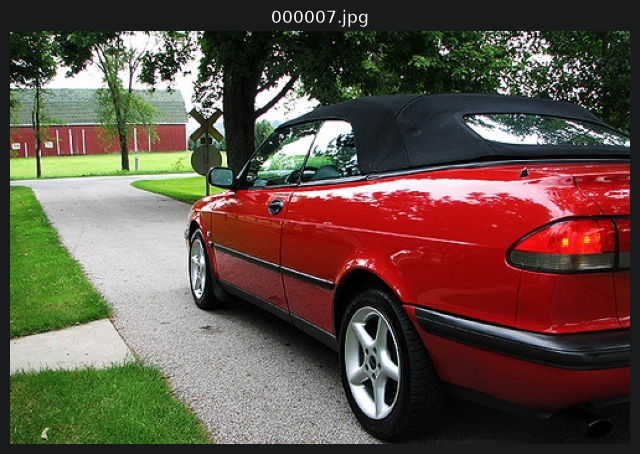

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from PIL import Image
from src.deep_models import getModel

candidates = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd().parent.parent,
]

ROOT_PATH = next(
    (p for p in candidates if (p / "data" / "images").exists()),
    Path.cwd()
)

image_path = ROOT_PATH / "data/images/000007.jpg"
if not image_path.exists():
    raise FileNotFoundError(f"Image not found: {image_path}")
if not image_path.exists():
    raise FileNotFoundError(f"Image not found: {image_path}")

image = Image.open(image_path).convert("RGB")

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")


print(f"Using device: {device}")
print(f"Image size: {image.size}")

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title(image_path.name)
plt.show()

## ResNet-18 Intermediate Features and CAM

The feature extractor records outputs from compound blocks during a forward pass.
For ResNet-18, `layer4.1` is the final convolutional block and produces the feature
map used below for class activation visualization.

### Inspect Intermediate Feature Maps

The extractor returns the model logits together with a dictionary keyed by the
captured block name. The spatial resolution decreases through the ResNet stages,
while the channel count increases. These tensors are useful for comparing early
and late visual representations.

In [2]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torchinfo import summary
from torchvision.models import ResNet18_Weights

from src.deep_models import IntermediateFeatureExtractor, getModel

# Keep the pretrained preprocessing that matches the model weights.
resnet, preprocess = getModel("resnet18", device=device, nofc=False)
print(summary(resnet, input_size=(1, 3, 224, 224), depth=2, device=device))

# Simple inference with the ResNet-18 model to get class probabilities.
transformed_image = preprocess(image).unsqueeze(0).to(device)
with torch.inference_mode():
    logits = resnet(transformed_image)
    # Convert logits into class probabilities.
    probabilities = torch.softmax(logits, dim=1)

    # Select the five most likely ImageNet classes.
    top_probabilities, top_indices = probabilities[0].topk(5)

    # Retrieve the class names associated with the predicted indices.
    categories = ResNet18_Weights.DEFAULT.meta["categories"]

    # Display the predictions and their confidence scores.
    print("Top predictions:")
    for probability, index in zip(top_probabilities, top_indices):
        print(f"{categories[index.item()]}: {probability.item():.2%}")

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 1000]                 --
├─Conv2d: 1-1                            [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 64, 56, 56]           --
│    └─BasicBlock: 2-1                   [1, 64, 56, 56]           73,984
│    └─BasicBlock: 2-2                   [1, 64, 56, 56]           73,984
├─Sequential: 1-6                        [1, 128, 28, 28]          --
│    └─BasicBlock: 2-3                   [1, 128, 28, 28]          230,144
│    └─BasicBlock: 2-4                   [1, 128, 28, 28]          295,424
├─Sequential: 1-7                        [1, 256, 14, 14]          --
│    └─BasicBlock: 2-5                   [1, 256, 14, 14]      

In [3]:
# Extract intermediate feature maps from the ResNet-18 model.
###############################################################################
extractor = IntermediateFeatureExtractor(resnet)
with torch.inference_mode():
    logits, intermediate = extractor(transformed_image)

print("Captured blocks:", list(intermediate))
for layer_name in ("layer2.1", "layer3.1", "layer4.1"):
    feature_map = intermediate[layer_name]
    print(f"{layer_name} feature map: {tuple(feature_map.shape)}")
print(f"Logits shape: {tuple(logits.shape)}")

Captured blocks: ['layer1.0', 'layer1.1', 'layer2.0', 'layer2.1', 'layer3.0', 'layer3.1', 'layer4.0', 'layer4.1']
layer2.1 feature map: (1, 128, 28, 28)
layer3.1 feature map: (1, 256, 14, 14)
layer4.1 feature map: (1, 512, 7, 7)
Logits shape: (1, 1000)


In [ ]:
# Class Activation Map (CAM) visualization for ResNet-18.
classes = ResNet18_Weights.DEFAULT.meta["categories"]


def resnet_cam(image, extractor, preprocess, target_class, classes, device):
    """Display a normalized ResNet-18 CAM for one ImageNet target class."""
    target_index = classes.index(target_class)
    image_tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        _, features = extractor(image_tensor)
        feature_map = features["layer4.1"]
        weights = extractor.model.fc.weight[target_index]
        cam = F.relu((feature_map[0] * weights[:, None, None]).sum(dim=0))
        cam = F.interpolate(
            cam[None, None],
            size=(image.height, image.width),
            mode="bilinear",
            align_corners=False,
        )[0, 0].cpu()
        cam = cam / cam.max().clamp_min(1e-8)

    print(f"Target class: {target_class} ({target_index})")
    print(f"CAM shape: {tuple(cam.shape)}")

    fig, axis = plt.subplots(figsize=(9, 6))
    axis.imshow(image)
    axis.imshow(cam, cmap="jet", alpha=0.5, vmin=0, vmax=1)
    axis.set_title(f"ResNet-18 CAM: {target_class}")
    axis.axis("off")
    plt.show()
    return cam


initial_class = classes[top_indices[0].item()]

target_class = widgets.Combobox(
    options=classes,
    value=initial_class,
    description="Class:",
    ensure_option=True,
    continuous_update=False,
    layout=widgets.Layout(width="500px"),
)
output = widgets.Output()


def update_cam(change):
    if change["name"] == "value" and change["new"]:
        with output:
            output.clear_output(wait=True)
            resnet_cam(image, extractor, preprocess, change["new"], classes, device)


target_class.observe(update_cam, names="value")
display(target_class, output)
update_cam({"name": "value", "new": initial_class})

Combobox(value='convertible', continuous_update=False, description='Class:', ensure_option=True, layout=Layout…

Output()

## Compare Feature Backbones

DINOv2 and CLIP provide alternative pretrained representations. These cells load
the models on the selected device and print their architecture summaries. DINOv2
may download weights from Torch Hub the first time it is used.

The summaries below are architectural inspections, not a benchmark. For a fair
embedding comparison, apply each model's returned preprocessing transform and
measure the resulting feature tensor on the same image.

In [5]:
dinov2, dino_preprocess = getModel("dinov2_vits14", device=device)
print(summary(dinov2, input_size=(1, 3, 224, 224), depth=2, device=device))

Using cache found in /Users/arthursophiatti/.cache/torch/hub/facebookresearch_dinov2_main


Layer (type:depth-idx)                   Output Shape              Param #
DinoVisionTransformer                    [1, 384]                  526,848
├─PatchEmbed: 1-1                        [1, 256, 384]             --
│    └─Conv2d: 2-1                       [1, 384, 16, 16]          226,176
│    └─Identity: 2-2                     [1, 256, 384]             --
├─ModuleList: 1-2                        --                        --
│    └─NestedTensorBlock: 2-3            [1, 257, 384]             1,775,232
│    └─NestedTensorBlock: 2-4            [1, 257, 384]             1,775,232
│    └─NestedTensorBlock: 2-5            [1, 257, 384]             1,775,232
│    └─NestedTensorBlock: 2-6            [1, 257, 384]             1,775,232
│    └─NestedTensorBlock: 2-7            [1, 257, 384]             1,775,232
│    └─NestedTensorBlock: 2-8            [1, 257, 384]             1,775,232
│    └─NestedTensorBlock: 2-9            [1, 257, 384]             1,775,232
│    └─NestedTensorBlock: 

In [6]:
clip_model, clip_preprocess = getModel("clip_vit_b_32", device=device)
print(summary(clip_model, depth=2))
print(summary(clip_model.visual, depth=3))
print(summary(clip_model.transformer, depth=2))

/Users/arthursophiatti/Library/CloudStorage/GoogleDrive-arthurtucogss@gmail.com/My Drive/Universidade/Mestrado/2 Ano/IA para Visão por Computador/Assig_2/.venv/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Layer (type:depth-idx)                                                 Param #
CLIP                                                                   301,569
├─VisionTransformer: 1-1                                               432,384
│    └─Conv2d: 2-1                                                     2,359,296
│    └─LayerNorm: 2-2                                                  1,536
│    └─Transformer: 2-3                                                85,054,464
│    └─LayerNorm: 2-4                                                  1,536
├─Transformer: 1-2                                                     --
│    └─Sequential: 2-5                                                 37,828,608
├─Embedding: 1-3                                                       25,296,896
├─LayerNorm: 1-4                                                       1,024
Total params: 151,277,313
Trainable params: 151,277,313
Non-trainable params: 0
Layer (type:depth-idx)                             

## CLIP Zero-Shot Classification

CLIP compares an image embedding with text embeddings in the same representation
space. The labels below are only an example; replace them with any candidate
descriptions relevant to the reference image. The scores are relative to this
candidate list and are not calibrated class probabilities.

In [7]:
import clip

candidate_labels = [
    "a photo of an aeroplane",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a motorbike",
    "a photo of a person",
    "a photo of a background scene",
]

text_tokens = clip.tokenize(candidate_labels).to(device)
image_tensor = clip_preprocess(image).unsqueeze(0).to(device)

with torch.inference_mode():
    image_features = clip_model.encode_image(image_tensor)
    text_features = clip_model.encode_text(text_tokens)
    image_features = image_features / image_features.norm(dim=-1, keepdim=True)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)
    scores = (100.0 * image_features @ text_features.T).softmax(dim=-1)[0]

ranking = torch.argsort(scores, descending=True)
print("Zero-shot ranking:")
for rank, label_index in enumerate(ranking, start=1):
    print(f"{rank}. {candidate_labels[label_index]}: {scores[label_index].item():.3f}")

Zero-shot ranking:
1. a photo of a car: 0.939
2. a photo of a background scene: 0.041
3. a photo of a horse: 0.013
4. a photo of a person: 0.004
5. a photo of a motorbike: 0.001
6. a photo of an aeroplane: 0.001


# Part 4 — Frozen pretrained representations: CNN, ViT, DINOv2, CLIP
**Protocol** (same as notebook 1): the provided `val` split is the held-out **test** set, used once for reporting;
C is chosen on a stratified `dev` split carved from `train`; one-vs-rest tasks = category vs `background`;
5-way confusion/F1 use the val images that belong to exactly one category (multi-label images excluded).
All features are cached in `data/features/` and L2-normalised before the linear SVM.

In [8]:
import time, warnings
import numpy as np, pandas as pd
from PIL import Image
import sklearn, torchvision
warnings.filterwarnings("ignore")
from src import eval as ev
from src.deep_models import extractEmbeddings

DATA = str(ROOT_PATH / "data"); FEAT = ROOT_PATH / "data" / "features"; FEAT.mkdir(exist_ok=True)
RES = ROOT_PATH / "code" / "results"; RES.mkdir(exist_ok=True)
pd.set_option("display.width", 220)
table = ev.split_table(DATA); names = table.name.values
paths = [f"{DATA}/images/{n}.jpg" for n in names]
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | sklearn {sklearn.__version__} | device {device}")
print(table.groupby("split")[ev.ALL_CATS].sum().T)

torch 2.14.0 | torchvision 0.29.0 | sklearn 1.9.1 | device mps
split       train   val
background   1019  1077
motorbike     120   125
aeroplane     112   126
person       1025   983
car           376   337
horse         139   148


In [9]:
def get_feats(model_name, flip=False):
    # cache: extraction runs once per model; time = decode + preprocess + forward (no model loading)
    f = FEAT / f"{model_name}{'_flip' if flip else ''}.npz"
    if not f.exists():
        feats, sec = extractEmbeddings(model_name, paths, device, flip=flip)
        np.savez(f, names=names, sec_per_img=sec, device=str(device), **feats)
    z = np.load(f, allow_pickle=True)
    assert (z["names"] == names).all()
    return {k: z[k] for k in z.files if k not in ("names", "sec_per_img", "device")}, float(z["sec_per_img"])

MODELS = ["resnet18", "vit_b_32", "dinov2_vits14", "clip_vit_b_32"]
REPS = {  # name -> (model, feature key); picked a priori, never by test score
    "ResNet-18 GAP(l2,l3,l4)": ("resnet18", "resnet18_gap3"), "ResNet-18 GAP(l4)": ("resnet18", "resnet18_l4"),
    "ViT-B/32 CLS": ("vit_b_32", "vit_b_32_cls"), "ViT-B/32 GAP(last 3)": ("vit_b_32", "vit_b_32_gap3"),
    "DINOv2 CLS": ("dinov2_vits14", "dinov2_cls"), "DINOv2 patch-mean": ("dinov2_vits14", "dinov2_patchmean"),
    "CLIP image emb": ("clip_vit_b_32", "clip_img"),
}
FE, SEC = {}, {}
for m in MODELS:
    FE[m], SEC[m] = get_feats(m)
F = {r: FE[m][k] for r, (m, k) in REPS.items()}
print(pd.DataFrame({r: dict(dim=F[r].shape[1], ms_per_img=1e3 * SEC[REPS[r][0]],
                            cache_MB=F[r].nbytes / 2**20) for r in REPS}).T.round(2))
print("(timings on", device, "; first model includes warm-up; includes image decode + preprocessing)")

Using cache found in /Users/arthursophiatti/.cache/torch/hub/facebookresearch_dinov2_main


                            dim  ms_per_img  cache_MB
ResNet-18 GAP(l2,l3,l4)   896.0        3.51     16.91
ResNet-18 GAP(l4)         512.0        3.51      9.66
ViT-B/32 CLS              768.0        5.46     14.49
ViT-B/32 GAP(last 3)     2304.0        5.46     43.47
DINOv2 CLS                384.0        7.56      7.25
DINOv2 patch-mean         384.0        7.56      7.25
CLIP image emb            512.0        6.22      9.66
(timings on mps ; first model includes warm-up; includes image decode + preprocessing)


## Stage D — SVM regularisation C (run first: it fixes C for A/B)
Train AP vs dev AP for C in {0.1,1,10,100,1000}; C is chosen per (representation, category) on dev AP.

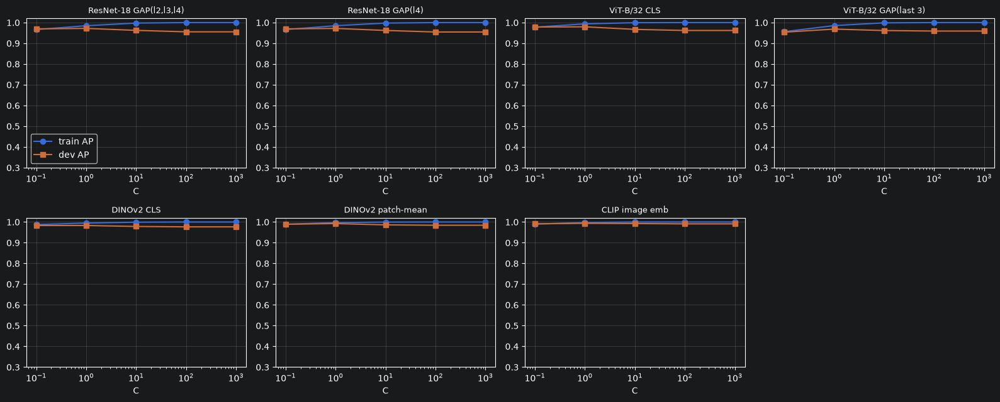

C,0.1,1.0,10.0,100.0,1000.0
rep,,,,,
CLIP image emb,0.991,0.994,0.993,0.991,0.991
DINOv2 CLS,0.983,0.983,0.979,0.977,0.977
DINOv2 patch-mean,0.989,0.993,0.986,0.984,0.984
"ResNet-18 GAP(l2,l3,l4)",0.970,0.972,0.962,0.955,0.955
ResNet-18 GAP(l4),0.970,0.972,0.962,0.955,0.955
ViT-B/32 CLS,0.979,0.980,0.967,0.962,0.962
ViT-B/32 GAP(last 3),0.954,0.969,0.962,0.959,0.959


In [10]:
import matplotlib.pyplot as plt
rows = []
for r in REPS:
    ld = ev.make_loader(F[r], table)
    for c in ev.CATEGORIES:
        Xtr, ytr, ntr = ld(c)["train"]; Xtr = ev.l2(Xtr)
        (Xa, ya, _), (Xd, yd, _) = ev.train_dev_split(Xtr, ytr, ntr)
        _, df = ev.select_C(Xa, ya, Xd, yd); df["rep"], df["category"] = r, c; rows.append(df)
D = pd.concat(rows)
curves = D.groupby(["rep", "C"])[["train_ap", "dev_ap"]].mean().reset_index()
fig, axs = plt.subplots(2, 4, figsize=(16, 6.5)); axs = axs.ravel()
for ax, r in zip(axs, REPS):
    a = curves[curves.rep == r]
    ax.semilogx(a.C, a.train_ap, "o-", label="train AP"); ax.semilogx(a.C, a.dev_ap, "s-", label="dev AP")
    ax.set_title(r, fontsize=9); ax.set_ylim(0.3, 1.02); ax.grid(alpha=.3); ax.set_xlabel("C")
axs[0].legend(); axs[-1].axis("off"); plt.tight_layout(); plt.show()
display(D.pivot_table(index="rep", columns="C", values="dev_ap").round(3))
D.to_csv(RES / "part4_stageD_C_curves.csv", index=False)

## Stage A/B — Linear SVM on frozen features: per-class AP, mAP, confusion matrix, cost

In [11]:
R = pd.DataFrame([dict(rep=r, **ev.run(r, c, norm="l2", loader=ev.make_loader(F[r], table)))
                  for r in REPS for c in ev.CATEGORIES])
Ctab = R.pivot(index="rep", columns="category", values="C").loc[list(REPS)]
AP = R.pivot(index="rep", columns="category", values="test_ap").loc[list(REPS)]
conf, f1 = {}, {}
for r in REPS:
    S, true, rows_ = ev.ovr_scores(F[r], table, Ctab.loc[r].to_dict())
    conf[r] = ev.multiclass_confusion(S, true, ev.CATEGORIES); f1[r] = ev.macro_f1(S, true)
cost = R.groupby("rep").agg(dim=("dim", "first"), train_s=("train_s", "mean"), infer_ms=("infer_ms_per_img", "mean"), test_feat_MB=("test_MB", "first"))
cost["extract_ms_per_img"] = [1e3 * SEC[REPS[r][0]] for r in cost.index]
A = AP.assign(mAP=AP.mean(1), macroF1_5way=pd.Series(f1)).join(cost).loc[list(REPS)]
display(A.round(4)); display(Ctab)
A.to_csv(RES / "part4_svm_table.csv")
for r in ("ResNet-18 GAP(l2,l3,l4)", "ViT-B/32 CLS", "DINOv2 CLS"):
    print(f"\nConfusion (rows=true, cols=pred), {r}, {len(true)} single-label val images"); display(conf[r])

,aeroplane,car,horse,motorbike,person,mAP,macroF1_5way,dim,train_s,infer_ms,test_feat_MB,extract_ms_per_img
rep,,,,,,,,,,,,
"ResNet-18 GAP(l2,l3,l4)",0.9755,0.9646,0.9324,0.9815,0.9739,0.9656,0.7441,896,0.0174,0.0002,4.1084,3.5079
ResNet-18 GAP(l4),0.9757,0.9645,0.9322,0.9817,0.9737,0.9656,0.7481,512,0.0102,0.0001,2.3477,3.5079
ViT-B/32 CLS,0.9944,0.9700,0.9666,0.9814,0.9597,0.9744,0.7516,768,0.0186,0.0002,3.5215,5.4588
ViT-B/32 GAP(last 3),0.9521,0.9398,0.9263,0.9493,0.9722,0.9479,0.7893,2304,0.0640,0.0006,10.5645,5.4588
DINOv2 CLS,1.0000,0.9765,0.9980,0.9820,0.9820,0.9877,0.8085,384,0.0081,0.0001,1.7607,7.5595
DINOv2 patch-mean,0.9997,0.9785,0.9913,0.9879,0.9902,0.9895,0.8941,384,0.0081,0.0001,1.7607,7.5595
CLIP image emb,0.9961,0.9776,0.9890,0.9933,0.9929,0.9898,0.9297,512,0.0096,0.0001,2.3477,6.2241


category,aeroplane,car,horse,motorbike,person
rep,,,,,
"ResNet-18 GAP(l2,l3,l4)",0.1,1.0,0.1,1.0,1.0
ResNet-18 GAP(l4),0.1,1.0,0.1,1.0,1.0
ViT-B/32 CLS,0.1,0.1,1.0,10.0,1.0
ViT-B/32 GAP(last 3),1.0,1.0,1.0,10.0,1.0
DINOv2 CLS,0.1,0.1,0.1,1.0,1.0
DINOv2 patch-mean,0.1,1.0,1.0,1.0,1.0
CLIP image emb,0.1,0.1,1.0,1.0,1.0



Confusion (rows=true, cols=pred), ResNet-18 GAP(l2,l3,l4), 1092 single-label val images


,motorbike,aeroplane,person,car,horse
motorbike,23,0,11,2,1
aeroplane,2,79,26,5,0
person,2,5,646,19,12
car,1,2,22,201,2
horse,0,0,19,0,12



Confusion (rows=true, cols=pred), ViT-B/32 CLS, 1092 single-label val images


,motorbike,aeroplane,person,car,horse
motorbike,23,0,13,0,1
aeroplane,1,97,14,0,0
person,10,12,645,14,3
car,1,1,134,92,0
horse,0,0,5,1,25



Confusion (rows=true, cols=pred), DINOv2 CLS, 1092 single-label val images


,motorbike,aeroplane,person,car,horse
motorbike,31,0,5,1,0
aeroplane,0,83,29,0,0
person,4,3,659,14,4
car,2,1,88,136,1
horse,0,0,9,0,22


In [12]:
# Precision / recall at a stated operating threshold (score > 0) + P@K / R@K per task
rows = []
for r in ("ResNet-18 GAP(l2,l3,l4)", "ViT-B/32 CLS", "DINOv2 CLS"):
    ld = ev.make_loader(F[r], table)
    for c in ev.CATEGORIES:
        d = ld(c); Xtr, ytr, _ = d["train"]; Xte, yte, _ = d["test"]
        W, b, _ = ev.fit(ev.l2(Xtr), ytr, C=Ctab.loc[r, c]); s = ev.score(W, b, ev.l2(Xte))
        rows.append(dict(rep=r, category=c, **ev.precision_recall_at(yte, s, 0.0),
                         **{f"P@{k}": ev.precision_at_k(yte, s, k) for k in (5, 10, 20)},
                         **{f"R@{k}": ev.recall_at_k(yte, s, k) for k in (10, 50)}))
PR = pd.DataFrame(rows); display(PR.round(3)); PR.to_csv(RES / "part4_pr_atk.csv", index=False)

,rep,category,precision,recall,P@5,P@10,P@20,R@10,R@50
0,"ResNet-18 GAP(l2,l3,l4)",motorbike,0.991,0.880,1.0,1.0,1.0,0.080,0.400
1,"ResNet-18 GAP(l2,l3,l4)",aeroplane,1.000,0.556,1.0,1.0,1.0,0.079,0.397
2,"ResNet-18 GAP(l2,l3,l4)",person,0.958,0.860,1.0,1.0,1.0,0.010,0.051
3,"ResNet-18 GAP(l2,l3,l4)",car,0.939,0.861,1.0,1.0,1.0,0.030,0.148
4,"ResNet-18 GAP(l2,l3,l4)",horse,1.000,0.169,1.0,1.0,1.0,0.068,0.338
5,ViT-B/32 CLS,motorbike,0.957,0.896,1.0,1.0,1.0,0.080,0.400
6,ViT-B/32 CLS,aeroplane,1.000,0.833,1.0,1.0,1.0,0.079,0.397
7,ViT-B/32 CLS,person,0.922,0.845,1.0,1.0,1.0,0.010,0.051
8,ViT-B/32 CLS,car,0.988,0.727,1.0,1.0,1.0,0.030,0.148
9,ViT-B/32 CLS,horse,0.983,0.777,1.0,1.0,1.0,0.068,0.338


## Stage C — Few-shot learning and horizontal-flip augmentation
Representation chosen a priori: **DINOv2 CLS** (self-supervised, strongest expected frozen feature), compared with ResNet-18 and
handcrafted BoVW (Hellinger). Positives: n in {1,5,10,20,50,all} sampled from `train`; **negatives: 200 images sampled at random from
`background_train` (per seed)**, `class_weight="balanced"`, fixed C=1 (no tuning on test). Flip augmentation = add the flipped copy of every
*training* image only. 5 seeds. AP on the provided val split.

Using cache found in /Users/arthursophiatti/.cache/torch/hub/facebookresearch_dinov2_main


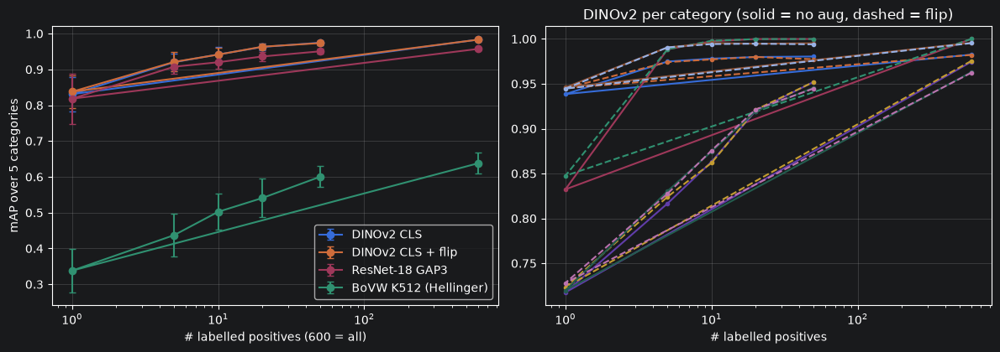

n_pos,-1,1,5,10,20,50
setup,,,,,,
BoVW K512 (Hellinger),0.638,0.338,0.437,0.502,0.541,0.600
DINOv2 CLS,0.983,0.831,0.920,0.942,0.963,0.975
DINOv2 CLS + flip,0.983,0.838,0.921,0.941,0.963,0.974
ResNet-18 GAP3,0.957,0.818,0.908,0.920,0.936,0.951


n_pos,-1,1,5,10,20,50
setup,,,,,,
BoVW K512 (Hellinger),0.029,0.061,0.059,0.051,0.054,0.029
DINOv2 CLS,0.002,0.048,0.025,0.021,0.009,0.005
DINOv2 CLS + flip,0.002,0.045,0.027,0.020,0.008,0.005
ResNet-18 GAP3,0.004,0.070,0.019,0.019,0.012,0.007


In [13]:
FDF, _ = get_feats("dinov2_vits14", flip=True); Ff = FDF["dinov2_cls"]

def bovw_matrix(enc="bovw_K512_C0"):
    d = {}
    for c in ev.ALL_CATS:
        for sp in ("train", "val"):
            z = np.load(f"{DATA}/encodings/{enc}/{c}_{sp}.npz"); d.update(zip(map(str, z["file_names"]), z["histograms"]))
    return np.stack([d[str(n)] for n in names])
F_bovw = bovw_matrix()

def few_shot(Fm, norm, cat, n_pos, seed, Fflip=None, C=1.0, n_neg=200):
    rng = np.random.default_rng(seed)
    idx, y = ev.task_idx(table, cat, "train")
    pos, neg = idx[y > 0], idx[y < 0]
    p = rng.choice(pos, min(n_pos, len(pos)), replace=False)
    sel = np.r_[p, rng.choice(neg, n_neg, replace=False)]
    ysel = np.r_[np.ones(len(p), int), -np.ones(n_neg, int)]
    X = Fm[sel]
    if Fflip is not None:
        X, ysel = np.vstack([X, Fflip[sel]]), np.r_[ysel, ysel]
    W, b = ev.utils.train_svm(ev.NORMS[norm](X), ysel, C=C, class_weight="balanced")
    ti, ty = ev.task_idx(table, cat, "val")
    return ev.ap(ty, ev.score(W, b, ev.NORMS[norm](Fm[ti])))

NPOS = (1, 5, 10, 20, 50, 10**6)
setups = {"DINOv2 CLS": (F["DINOv2 CLS"], "l2", None), "DINOv2 CLS + flip": (F["DINOv2 CLS"], "l2", Ff),
          "ResNet-18 GAP3": (F["ResNet-18 GAP(l2,l3,l4)"], "l2", None), "BoVW K512 (Hellinger)": (F_bovw, "hellinger", None)}
FS = pd.DataFrame([dict(setup=k, category=c, n_pos=n, seed=s, ap=few_shot(Fm, nm, c, n, s, Fl))
                   for k, (Fm, nm, Fl) in setups.items() for c in ev.CATEGORIES for n in NPOS for s in range(5)])
FS["n_pos"] = FS.n_pos.where(FS.n_pos < 10**6, -1)
by_cat = FS.groupby(["setup", "n_pos", "category"]).ap.agg(["mean", "std"]).reset_index()
agg = by_cat.groupby(["setup", "n_pos"])[["mean", "std"]].mean().reset_index()   # mean over categories
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
for k in setups:
    a = agg[agg.setup == k].replace({-1: 600}); axs[0].errorbar(a.n_pos, a["mean"], a["std"], marker="o", capsize=3, label=k)
axs[0].set_xscale("log"); axs[0].set_xlabel("# labelled positives (600 = all)"); axs[0].set_ylabel("mAP over 5 categories"); axs[0].legend(); axs[0].grid(alpha=.3)
for c in ev.CATEGORIES:
    for k, ls in (("DINOv2 CLS", "-"), ("DINOv2 CLS + flip", "--")):
        a = by_cat[(by_cat.setup == k) & (by_cat.category == c)].replace({-1: 600}); axs[1].plot(a.n_pos, a["mean"], ls, marker=".", label=f"{c} {'flip' if 'flip' in k else ''}".strip())
axs[1].set_xscale("log"); axs[1].set_title("DINOv2 per category (solid = no aug, dashed = flip)"); axs[1].set_xlabel("# labelled positives"); axs[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
display(agg.pivot(index="setup", columns="n_pos", values="mean").round(3)); display(agg.pivot(index="setup", columns="n_pos", values="std").round(3))
FS.to_csv(RES / "part4_fewshot.csv", index=False)

In [14]:
# Test-time flip: averaging feature vectors vs averaging classifier scores
c = "motorbike"; ld = ev.make_loader(F["DINOv2 CLS"], table); Xtr, ytr, _ = ld(c)["train"]
W, b, _ = ev.fit(ev.l2(Xtr), ytr, C=1.0)
ti, ty = ev.task_idx(table, c, "val"); A_, B_ = F["DINOv2 CLS"][ti], Ff[ti]
s_scores = (ev.score(W, b, ev.l2(A_)) + ev.score(W, b, ev.l2(B_))) / 2                    # mean of scores
s_feat_l2each = ev.score(W, b, (ev.l2(A_) + ev.l2(B_)) / 2)                               # mean of unit-norm features -> linear => identical
s_feat_renorm = ev.score(W, b, ev.l2(ev.l2(A_) + ev.l2(B_)))                              # re-normalise after averaging -> differs
print("max |score-avg - feature-avg| (no renorm):", np.abs(s_scores - s_feat_l2each).max())
print("AP no TTA / score-avg / feat-avg+renorm:", round(ev.ap(ty, ev.score(W, b, ev.l2(A_))), 4), round(ev.ap(ty, s_scores), 4), round(ev.ap(ty, s_feat_renorm), 4))

max |score-avg - feature-avg| (no renorm): 3.8245951516913124e-08
AP no TTA / score-avg / feat-avg+renorm: 0.982 0.9836 0.9836


## Stage E — CLIP zero-shot (no task labels)
Prompt sets are compared on the **train split** (acts as validation; CLIP never sees labels) and the set is selected there; test numbers for all sets are shown only to measure wording sensitivity.

In [15]:
import clip
SYN = {"aeroplane": ["aeroplane", "airplane"], "car": ["car"], "horse": ["horse"], "motorbike": ["motorbike", "motorcycle"], "person": ["person"]}
TPL = ["a photo of a {}.", "a picture of a {}.", "a close-up photo of a {}.", "a low resolution photo of a {}.", "a photo of the {}.", "a cropped photo of a {}."]
PROMPTS = {
    "single (a photo of a X)": {c: [f"a photo of a {SYN[c][0]}"] for c in ev.CATEGORIES},
    "single, synonyms (airplane/motorcycle)": {c: [f"a photo of a {SYN[c][-1]}"] for c in ev.CATEGORIES},
    "bare class name": {c: [SYN[c][0]] for c in ev.CATEGORIES},
    "ensemble (6 templates x synonyms)": {c: [t.format(n) for t in TPL for n in SYN[c]] for c in ev.CATEGORIES},
    "descriptive": {"aeroplane": ["a photo of an airplane flying in the sky or parked at an airport"], "car": ["a photo of a car driving on a road"],
                    "horse": ["a photo of a horse standing in a field"], "motorbike": ["a photo of a motorcycle with a rider on a road"],
                    "person": ["a photo of a person"]},
}
def text_emb(texts):
    with torch.inference_mode():
        t = clip_model.encode_text(clip.tokenize(texts).to(device)).float().cpu().numpy()
    t = ev.l2(t); return ev.l2(t.mean(0, keepdims=True))[0]

Fc = ev.l2(F["CLIP image emb"])
def zs_eval(P, split):
    T = np.stack([text_emb(P[c]) for c in ev.CATEGORIES])                       # (5, 512)
    aps = {}
    for k, c in enumerate(ev.CATEGORIES):
        i, y = ev.task_idx(table, c, split); aps[c] = ev.ap(y, Fc[i] @ T[k])
    m = (table.split == split).values & table.single.values & ~table.background.values
    rows_ = np.where(m)[0]; true = table.loc[rows_, ev.CATEGORIES].values.argmax(1); S = Fc[rows_] @ T.T
    return aps, S, true

t0 = time.perf_counter(); _ = text_emb(PROMPTS["ensemble (6 templates x synonyms)"]["person"]); t_text = time.perf_counter() - t0
rows = []
for name, P in PROMPTS.items():
    for split in ("train", "val"):
        aps, S, true = zs_eval(P, split)
        rows.append(dict(prompts=name, split=split, mAP=np.mean(list(aps.values())), macroF1=ev.macro_f1(S, true), acc=(S.argmax(1) == true).mean(), **aps))
Z = pd.DataFrame(rows)
display(Z.round(3))
sel = Z[Z.split == "train"].set_index("prompts").mAP.idxmax(); print("prompt set selected on the TRAIN split:", sel)
aps, S, true = zs_eval(PROMPTS[sel], "val")
print("CLIP zero-shot (selected set) on test: mAP %.4f | macro-F1 %.4f | acc %.4f" % (np.mean(list(aps.values())), ev.macro_f1(S, true), (S.argmax(1) == true).mean()))
display(ev.multiclass_confusion(S, true, ev.CATEGORIES))
Z.to_csv(RES / "part4_clip_zeroshot.csv", index=False)
print(f"CLIP zero-shot cost: image encode {1e3*SEC['clip_vit_b_32']:.1f} ms/img | text encode (12 prompts) {1e3*t_text:.0f} ms once | scoring ~0 ms | dim 512")

,prompts,split,mAP,macroF1,acc,motorbike,aeroplane,person,car,horse
0,single (a photo of a X),train,0.851,0.762,0.859,0.951,0.979,0.631,0.859,0.836
1,single (a photo of a X),val,0.837,0.771,0.854,0.912,0.983,0.615,0.868,0.806
2,"single, synonyms (airplane/motorcycle)",train,0.843,0.790,0.879,0.935,0.956,0.631,0.859,0.836
3,"single, synonyms (airplane/motorcycle)",val,0.836,0.794,0.875,0.912,0.977,0.615,0.868,0.806
4,bare class name,train,0.852,0.655,0.735,0.945,0.969,0.580,0.847,0.919
5,bare class name,val,0.840,0.653,0.712,0.943,0.949,0.544,0.865,0.899
6,ensemble (6 templates x synonyms),train,0.827,0.792,0.878,0.930,0.979,0.557,0.857,0.811
7,ensemble (6 templates x synonyms),val,0.821,0.794,0.864,0.908,0.986,0.550,0.867,0.794
8,descriptive,train,0.793,0.879,0.925,0.979,0.929,0.631,0.845,0.583
9,descriptive,val,0.789,0.866,0.914,0.966,0.955,0.615,0.840,0.570


prompt set selected on the TRAIN split: bare class name
CLIP zero-shot (selected set) on test: mAP 0.8401 | macro-F1 0.6525 | acc 0.7125


,motorbike,aeroplane,person,car,horse
motorbike,36,0,0,0,1
aeroplane,0,112,0,0,0
person,85,127,387,46,39
car,6,5,4,212,1
horse,0,0,0,0,31


CLIP zero-shot cost: image encode 6.2 ms/img | text encode (12 prompts) 254 ms once | scoring ~0 ms | dim 512


## Stage F — Failure cases and visual explanations
Highest-scored negatives (false positives) and lowest-scored positives (false negatives) for the motorbike and horse tasks; DINOv2 patch
heat-map = patch tokens projected on the SVM weight vector; ResNet CAM = SVM weights over the layer4.1 feature maps (a CAM for the *task* classifier, not ImageNet).
Saliency maps show where evidence for the linear score comes from; they do not prove causality.

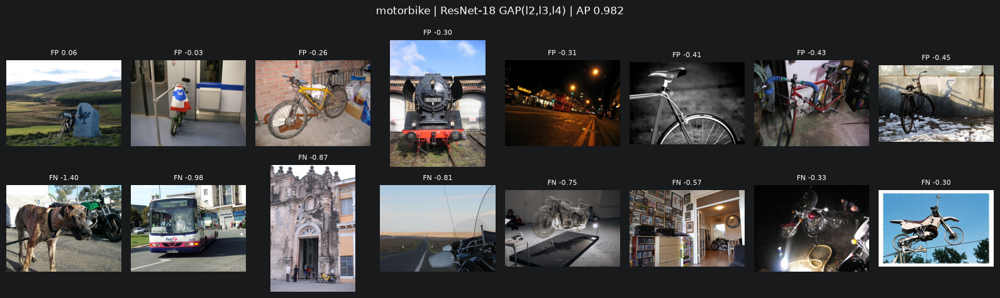

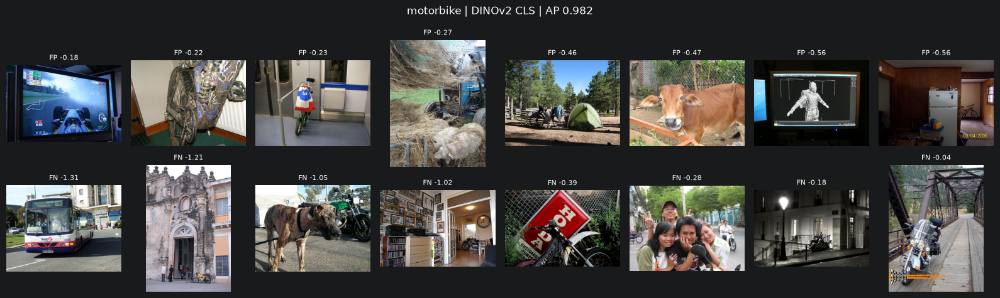

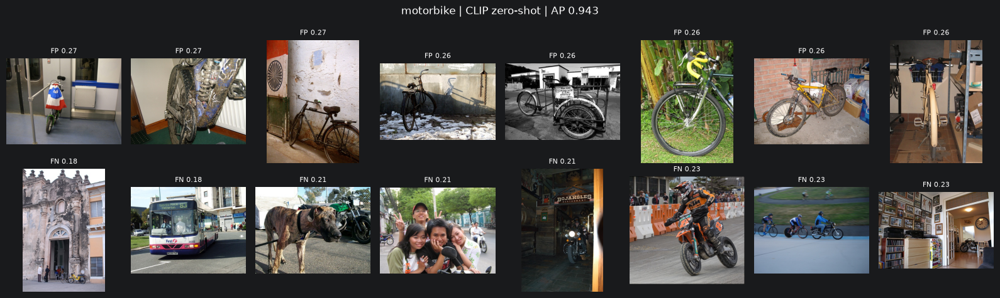

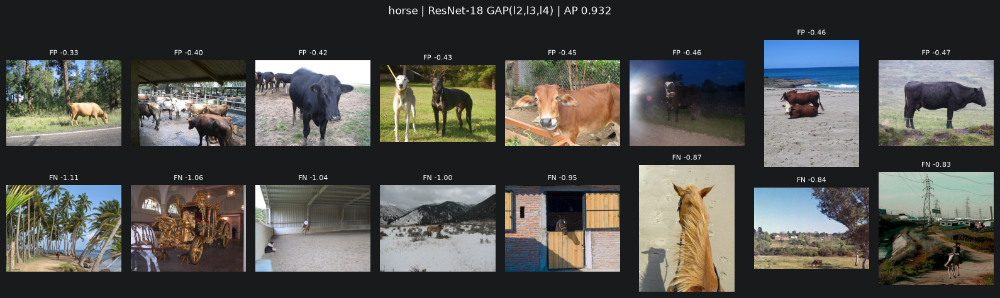

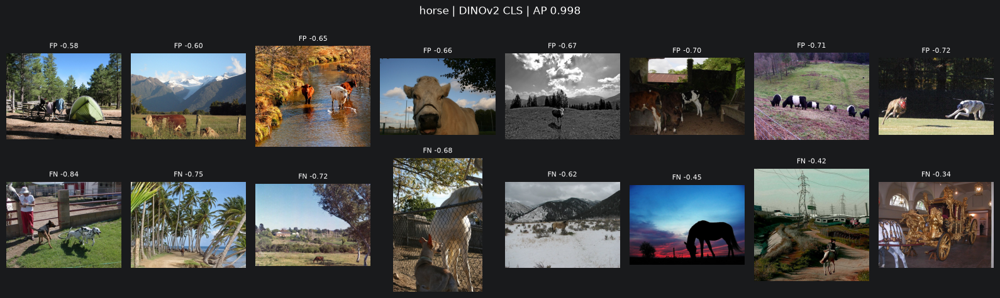

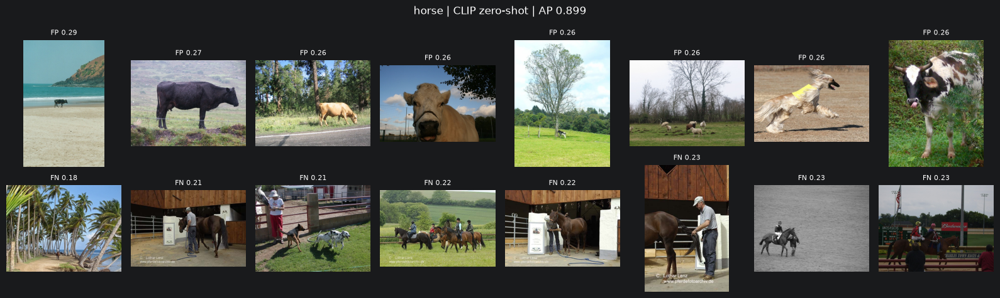

In [16]:
def task_scores(rep, cat):
    ld = ev.make_loader(F[rep], table); d = ld(cat); Xtr, ytr, _ = d["train"]
    W, b, _ = ev.fit(ev.l2(Xtr), ytr, C=Ctab.loc[rep, cat]); ti, ty = ev.task_idx(table, cat, "val")
    return W, b, ti, ty, ev.score(W, b, ev.l2(F[rep][ti]))

def clip_task_scores(cat):
    T = text_emb(PROMPTS[sel][cat]); ti, ty = ev.task_idx(table, cat, "val"); return ti, ty, Fc[ti] @ T

def show_errors(title, ti, ty, s, k=8):
    order = np.argsort(-s)
    fp = [i for i in order if ty[i] < 0][:k]; fn = [i for i in order[::-1] if ty[i] > 0][:k]
    fig, ax = plt.subplots(2, k, figsize=(2 * k, 4.8)); fig.suptitle(title)
    for r, (lst, lab) in enumerate(((fp, "FP"), (fn, "FN"))):
        for j, i in enumerate(lst):
            ax[r, j].imshow(Image.open(f"{DATA}/images/{names[ti[i]]}.jpg")); ax[r, j].axis("off"); ax[r, j].set_title(f"{lab} {s[i]:.2f}", fontsize=8)
    plt.tight_layout(); plt.show()

for cat in ("motorbike", "horse"):
    for rep in ("ResNet-18 GAP(l2,l3,l4)", "DINOv2 CLS"):
        W, b, ti, ty, s = task_scores(rep, cat); show_errors(f"{cat} | {rep} | AP {ev.ap(ty, s):.3f}", ti, ty, s)
    ti, ty, s = clip_task_scores(cat); show_errors(f"{cat} | CLIP zero-shot | AP {ev.ap(ty, s):.3f}", ti, ty, s)

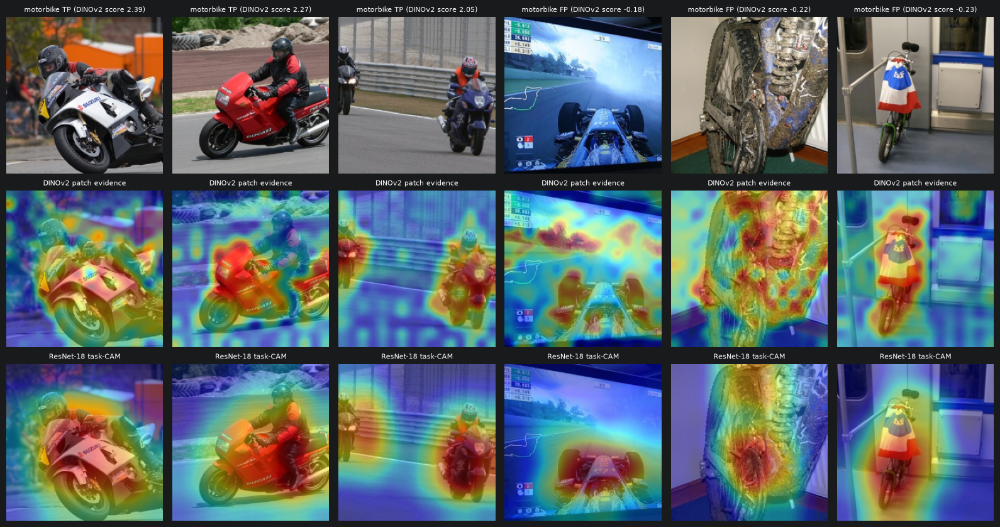

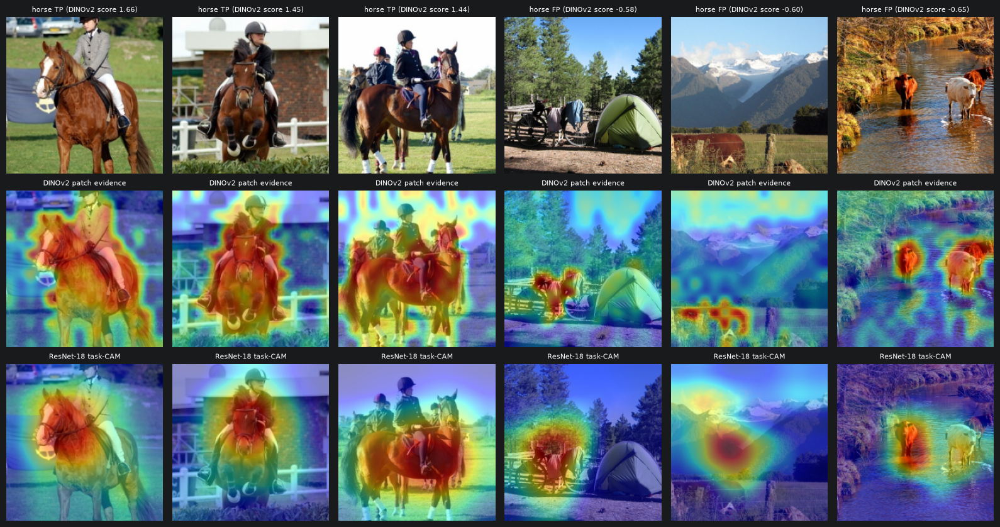

In [17]:
from torchvision import transforms as T
import cv2
disp = T.Compose([T.Resize(256), T.CenterCrop(224)])

def dino_heat(img, W):
    x = dino_preprocess(img).unsqueeze(0).to(device)
    with torch.inference_mode(): pt = dinov2.forward_features(x)["x_norm_patchtokens"][0].float().cpu().numpy()
    return (pt @ W).reshape(16, 16)

def resnet_heat(img, W):
    x = preprocess(img).unsqueeze(0).to(device)
    with torch.inference_mode(): _, f = extractor(x); A_ = f["layer4.1"][0].float().cpu().numpy()
    return np.maximum(np.tensordot(W, A_, axes=(0, 0)), 0)

def overlay(ax, img, h, title):
    h = cv2.resize(h.astype(np.float32), (224, 224), interpolation=cv2.INTER_CUBIC); h = (h - h.min()) / (np.ptp(h) + 1e-8)
    ax.imshow(disp(img)); ax.imshow(h, cmap="jet", alpha=0.45); ax.axis("off"); ax.set_title(title, fontsize=8)

for cat in ("motorbike", "horse"):
    Wd, bd, ti, ty, sd = task_scores("DINOv2 CLS", cat)
    Wr, br, _, _, sr = task_scores("ResNet-18 GAP(l4)", cat)
    order = np.argsort(-sd); tp = [i for i in order if ty[i] > 0][:3]; fp = [i for i in order if ty[i] < 0][:3]
    fig, ax = plt.subplots(3, 6, figsize=(16, 8.5))
    for j, (i, lab) in enumerate([(i, "TP") for i in tp] + [(i, "FP") for i in fp]):
        img = Image.open(f"{DATA}/images/{names[ti[i]]}.jpg").convert("RGB")
        ax[0, j].imshow(disp(img)); ax[0, j].axis("off"); ax[0, j].set_title(f"{cat} {lab} (DINOv2 score {sd[i]:.2f})", fontsize=8)
        overlay(ax[1, j], img, dino_heat(img, Wd), "DINOv2 patch evidence"); overlay(ax[2, j], img, resnet_heat(img, Wr), "ResNet-18 task-CAM")
    plt.tight_layout(); plt.show()

## Consolidated comparison table (required by the assignment)

In [18]:
p2 = pd.read_csv(RES / "part2_encodings.csv", index_col=0)      # produced by 1_handcraft.ipynb
rows = []
for name, key in (("BoVW + SVM (K=512, Hellinger)", "BoVW K512"), ("VLAD + SVM (K=32, PCA80)", "VLAD K32 PCA80"), ("Fisher Vector + SVM (K=32, PCA80)", "FV K32 PCA80")):
    r = p2.loc[key]; rows.append(dict(Method=name, Supervision="Task labels", mAP=r["mAP"], Dim=int(r["dim"]), Extraction="precomputed descriptors (dense SIFT, not re-timed)",
                                       Inference_ms_per_img=r["infer_ms_per_img"], Train_s=r["train_s"]))
for name, key in (("ResNet-18 (GAP l2-l4) + SVM", "ResNet-18 GAP(l2,l3,l4)"), ("ViT-B/32 (CLS) + SVM", "ViT-B/32 CLS"), ("DINOv2 ViT-S/14 (CLS) + SVM", "DINOv2 CLS"), ("CLIP ViT-B/32 image emb + SVM (extra)", "CLIP image emb")):
    r = A.loc[key]; rows.append(dict(Method=name, Supervision="Self-supervised + task labels" if "DINO" in name else "Pretrained + task labels", mAP=r["mAP"], Dim=int(r["dim"]),
                                      Extraction=f"{r['extract_ms_per_img']:.1f} ms/img ({device})", Inference_ms_per_img=r["infer_ms"], Train_s=r["train_s"]))
aps_zs, S_zs, true_zs = zs_eval(PROMPTS[sel], "val")
rows.append(dict(Method=f"CLIP zero-shot ({sel})", Supervision="Image-text pretraining; no task labels", mAP=np.mean(list(aps_zs.values())), Dim=512,
                 Extraction=f"{1e3*SEC['clip_vit_b_32']:.1f} ms/img ({device})", Inference_ms_per_img=0.0, Train_s=0.0))
final = pd.DataFrame(rows); display(final.round(4)); final.to_csv(RES / "final_comparison_table.csv", index=False)
print(final.round(4).to_markdown(index=False))

,Method,Supervision,mAP,Dim,Extraction,Inference_ms_per_img,Train_s
0,"BoVW + SVM (K=512, Hellinger)",Task labels,0.7163,2048,"precomputed descriptors (dense SIFT, not re-ti...",0.0002,0.0833
1,"VLAD + SVM (K=32, PCA80)",Task labels,0.7791,10240,"precomputed descriptors (dense SIFT, not re-ti...",0.0025,0.4372
2,"Fisher Vector + SVM (K=32, PCA80)",Task labels,0.7944,20608,"precomputed descriptors (dense SIFT, not re-ti...",0.0021,0.9595
3,ResNet-18 (GAP l2-l4) + SVM,Pretrained + task labels,0.9656,896,3.5 ms/img (mps),0.0002,0.0174
4,ViT-B/32 (CLS) + SVM,Pretrained + task labels,0.9744,768,5.5 ms/img (mps),0.0002,0.0186
5,DINOv2 ViT-S/14 (CLS) + SVM,Self-supervised + task labels,0.9877,384,7.6 ms/img (mps),0.0001,0.0081
6,CLIP ViT-B/32 image emb + SVM (extra),Pretrained + task labels,0.9898,512,6.2 ms/img (mps),0.0001,0.0096
7,CLIP zero-shot (bare class name),Image-text pretraining; no task labels,0.8401,512,6.2 ms/img (mps),0.0000,0.0000


| Method                                | Supervision                            |    mAP |   Dim | Extraction                                         |   Inference_ms_per_img |   Train_s |
|:--------------------------------------|:---------------------------------------|-------:|------:|:---------------------------------------------------|-----------------------:|----------:|
| BoVW + SVM (K=512, Hellinger)         | Task labels                            | 0.7163 |  2048 | precomputed descriptors (dense SIFT, not re-timed) |                 0.0002 |    0.0833 |
| VLAD + SVM (K=32, PCA80)              | Task labels                            | 0.7791 | 10240 | precomputed descriptors (dense SIFT, not re-timed) |                 0.0025 |    0.4372 |
| Fisher Vector + SVM (K=32, PCA80)     | Task labels                            | 0.7944 | 20608 | precomputed descriptors (dense SIFT, not re-timed) |                 0.0021 |    0.9595 |
| ResNet-18 (GAP l2-l4) + SVM           | Pretrain